# Laboratorio 12: AlexNet y aprendizaje por transferencia

**Estudiante:** Angela Jara · **Docente:** David Calderón · **Asignatura:** Software Inteligente

**Objetivo.** Analizar AlexNet preentrenada en ImageNet y comparar tres formas de entrenarla para
un problema específico: diagnosticar enfermedades en hojas de frijol a partir de fotografías.

**Enfoque.** Tres estrategias con los mismos datos, partición, preprocesamiento y conjunto de prueba:
(1) desde cero, (2) solo la capa clasificadora sobre pesos de ImageNet y (3) *fine-tuning* de
conv4–conv5. Todas usan SGD con momentum y parada temprana. El análisis teórico está en el informe
PDF (`informe/informe_lab12.pdf`).

| Indicación del laboratorio | Dónde se responde |
|---|---|
| Analizar un modelo preentrenado (excepto Xception) | Informe §1; notebook §3 |
| Condiciones de entrada | Informe §2.1; notebook §2 |
| Cantidad de bloques | Informe §2.2; notebook §3 |
| Cantidad de convoluciones | Informe §2.3; notebook §3 |
| Funciones de activación | Informe §2.4; notebook §3 |
| Funciones de optimización | Informe §2.5; notebook §4 |
| Parámetros configurables y su objetivo | Informe §2.6; notebook §1 |
| ¿Permite agregar capas? | Informe §2.7; notebook §6 |
| ¿Permite *fine-tuning*? | Informe §2.8; notebook §7 |
| ¿Permite entrenamiento específico? | Informe §2.9; notebook §6–§7 |
| Conjunto de datos | Notebook §2 |
| Entrenamiento desde cero | Notebook §5 |
| Solo entrenar la capa clasificadora | Notebook §6 |
| *Fine-tuning* congelando/descongelando convoluciones | Notebook §7 |

## 1. Configuración
Todos los valores ajustables están en una sola celda.

In [1]:
import copy, random, time, zipfile, urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets, models
from torchvision.transforms import v2
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Misma familia tipográfica que el informe (Nimbus Roman = Times)
plt.rcParams.update({"font.family": "serif",
                     "font.serif": ["Nimbus Roman", "Liberation Serif", "DejaVu Serif"],
                     "mathtext.fontset": "stix", "font.size": 11})

In [2]:
SEED = 42
IMG_SIZE = 224          # tamaño nativo de AlexNet
BATCH_SIZE = 32
MOMENTUM = 0.9          # igual que el artículo original
WEIGHT_DECAY = 5e-4     # igual que el artículo original
PATIENCE = 5            # épocas sin mejora de val_loss antes de detener
NUM_WORKERS = 4

# El LR baja a medida que se entrenan pesos más valiosos: aleatorios → capa nueva → convoluciones preentrenadas
ESTRATEGIAS = {
    "desde_cero":  {"lr": 1e-2, "max_epocas": 30},
    "extraccion":  {"lr": 1e-3, "max_epocas": 10},
    "fine_tuning": {"lr": 1e-4, "max_epocas": 10},
}
ETIQUETA = {"desde_cero": "Desde cero", "extraccion": "Solo capa clasificadora",
            "fine_tuning": "Fine-tuning conv4–conv5"}

DATA_DIR, CACHE_DIR = Path("data"), Path(".cache/torch")
FIG_DIR, GEN_DIR = Path("informe/figures"), Path("informe/generated")
URL_BEANS = "https://huggingface.co/datasets/AI-Lab-Makerere/beans/resolve/main/data/{}.zip"
PARTICIONES = ("train", "validation", "test")   # partición oficial del conjunto de datos
URL_PESOS = "https://download.pytorch.org/models/alexnet-owt-7be5be79.pth"
MEDIA_IMAGENET, STD_IMAGENET = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

In [3]:
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
torch.use_deterministic_algorithms(True, warn_only=True)
torch.hub.set_dir(str(CACHE_DIR))          # pesos ImageNet dentro de lab12/ (ignorado por git)
for d in (DATA_DIR, CACHE_DIR, FIG_DIR, GEN_DIR):
    d.mkdir(parents=True, exist_ok=True)
print(f"torch {torch.__version__} | hilos CPU: {torch.get_num_threads()}")

torch 2.15.0+cpu | hilos CPU: 10


> En CPU multihilo el orden de las sumas en coma flotante puede variar, por lo que las métricas pueden diferir levemente entre ejecuciones pese a las semillas fijas.

## 2. Datos

**Beans** (Makerere AI Lab, 2020, <https://github.com/AI-Lab-Makerere/ibean/>, licencia MIT):
fotografías reales de hojas de frijol tomadas en campo en Uganda, JPEG 500×500, 3 clases:
`angular_leaf_spot` (mancha angular), `bean_rust` (roya) y `healthy` (sana). Se usa su partición
oficial: entrenamiento, validación (para la parada temprana) y prueba (solo para la evaluación
final). No es una categoría de ImageNet, así que pone a prueba la transferencia a un dominio nuevo.
La descarga (~180 MB) ocurre solo la primera vez. El zip de entrenamiento trae un archivo que no
es imagen (`healthy_train.120tore`); `ImageFolder` lo ignora, por lo que `healthy` tiene 341 imágenes.

In [4]:
def descargar_y_extraer(particion):
    # Descarga el zip y lo extrae en data/beans/<particion>/; si la carpeta existe, reutiliza la caché.
    base, url = DATA_DIR / "beans", URL_BEANS.format(particion)
    destino = base / particion
    if destino.is_dir():
        return destino
    base.mkdir(parents=True, exist_ok=True)
    zip_path = base / f"{particion}.zip"
    try:
        urllib.request.urlretrieve(url, zip_path)
        with zipfile.ZipFile(zip_path) as zf:
            # archivo externo: se rechaza cualquier ruta fuera de data/beans/<particion>/
            if any(not m.startswith(f"{particion}/") or ".." in m for m in zf.namelist()):
                raise ValueError("estructura del zip inesperada")
            zf.extractall(base)
    except Exception as e:
        raise RuntimeError(f"No se pudo obtener {url}; se esperaba data/beans/{particion}/<clase>/") from e
    finally:
        zip_path.unlink(missing_ok=True)
    return destino

directorios = {p: descargar_y_extraer(p) for p in PARTICIONES}

**Condiciones de entrada.** RGB, 224×224, valores en [0, 1] normalizados con la media y desviación de ImageNet. El aumento de datos (recorte/zoom leve, volteo, rotación ±15°) se aplica solo a entrenamiento; validación y prueba solo se redimensionan.

In [5]:
normalizar = v2.Normalize(MEDIA_IMAGENET, STD_IMAGENET)
tf_eval = v2.Compose([v2.ToImage(), v2.Resize((IMG_SIZE, IMG_SIZE), antialias=True),
                      v2.ToDtype(torch.float32, scale=True), normalizar])
tf_train = v2.Compose([v2.ToImage(),
                       v2.RandomResizedCrop(IMG_SIZE, scale=(0.85, 1.0), antialias=True),
                       v2.RandomHorizontalFlip(),
                       v2.RandomRotation(15),
                       v2.ToDtype(torch.float32, scale=True), normalizar])

train_ds = datasets.ImageFolder(directorios["train"], transform=tf_train)
val_ds = datasets.ImageFolder(directorios["validation"], transform=tf_eval)
test_ds = datasets.ImageFolder(directorios["test"], transform=tf_eval)
CLASES = train_ds.classes
NOMBRE_CLASE = {"angular_leaf_spot": "mancha angular", "bean_rust": "roya", "healthy": "sana"}

def semilla_worker(_):
    s = torch.initial_seed() % 2**32
    np.random.seed(s); random.seed(s)

def crear_loader(ds, mezclar):
    # Solo el loader de entrenamiento mantiene sus procesos vivos entre épocas (ahorra memoria)
    return DataLoader(ds, batch_size=BATCH_SIZE, shuffle=mezclar, num_workers=NUM_WORKERS,
                      worker_init_fn=semilla_worker, generator=torch.Generator().manual_seed(SEED),
                      multiprocessing_context="fork" if NUM_WORKERS else None,
                      persistent_workers=mezclar and NUM_WORKERS > 0)

train_loader, val_loader, test_loader = (crear_loader(train_ds, True), crear_loader(val_ds, False),
                                         crear_loader(test_ds, False))

In [6]:
conteo = pd.DataFrame({"entrenamiento": np.bincount(train_ds.targets, minlength=3),
                       "validación": np.bincount(val_ds.targets, minlength=3),
                       "prueba": np.bincount(test_ds.targets, minlength=3)}, index=CLASES)
conteo.loc["total"] = conteo.sum()
display(conteo)

assert CLASES == ["angular_leaf_spot", "bean_rust", "healthy"]
assert val_ds.classes == CLASES and test_ds.classes == CLASES
assert np.bincount(train_ds.targets).tolist() == [345, 348, 341]
assert np.bincount(val_ds.targets).tolist() == [44, 45, 44]
assert np.bincount(test_ds.targets).tolist() == [43, 43, 42]

,entrenamiento,validación,prueba
angular_leaf_spot,345,44,43
bean_rust,348,45,43
healthy,341,44,42
total,1034,133,128


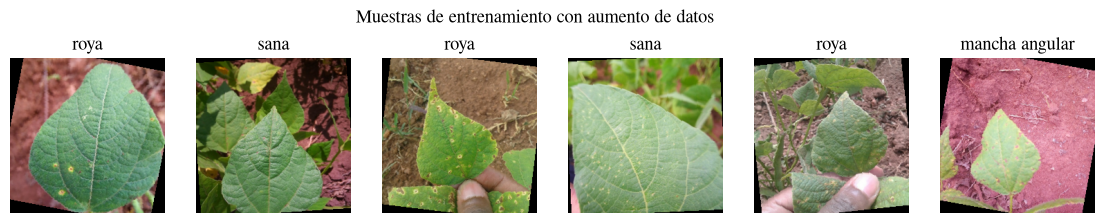

In [7]:
def desnormalizar(x):
    return (x * torch.tensor(STD_IMAGENET)[:, None, None]
            + torch.tensor(MEDIA_IMAGENET)[:, None, None]).clamp(0, 1)

fig, axes = plt.subplots(1, 6, figsize=(14, 2.6))
for ax, i in zip(axes, np.random.default_rng(SEED).choice(len(train_ds), 6, replace=False)):
    x, y = train_ds[i]
    ax.imshow(desnormalizar(x).permute(1, 2, 0)); ax.set_title(NOMBRE_CLASE[CLASES[y]]); ax.axis("off")
fig.suptitle("Muestras de entrenamiento con aumento de datos"); plt.show()

## 3. Arquitectura de AlexNet

torchvision implementa la variante de Krizhevsky (2014): 64-192-384-256-256 filtros, sin LRN ni
convoluciones agrupadas. Al no tener bloques con nombre, se cuentan como **bloques las etapas
cerradas por max-pooling**:

| Etapa | Capas | Activación |
|---|---|---|
| 1 | conv1 → pool1 | ReLU |
| 2 | conv2 → pool2 | ReLU |
| 3 | conv3 → conv4 → conv5 → pool3 | ReLU |
| Clasificador | avgpool 6×6 → dropout → dense1 → dropout → dense2 → dense3 | ReLU en dense1–2; softmax implícito en la pérdida |

In [8]:
NOMBRES = {"features.0": "conv1", "features.2": "pool1", "features.3": "conv2", "features.5": "pool2",
           "features.6": "conv3", "features.8": "conv4", "features.10": "conv5", "features.12": "pool3",
           "avgpool": "avgpool", "classifier.1": "dense1", "classifier.4": "dense2",
           "classifier.6": "dense3"}
ETAPA = {"conv1": "1", "pool1": "1", "conv2": "2", "pool2": "2", "conv3": "3", "conv4": "3",
         "conv5": "3", "pool3": "3", "avgpool": "--", "dense1": "Clasif.", "dense2": "Clasif.",
         "dense3": "Clasif."}

alexnet = models.alexnet(weights=None)      # cabeza original de 1000 clases
print(alexnet)

AlexNet(
  (features): Sequential(
    (0): Conv2d(3, 64, kernel_size=(11, 11), stride=(4, 4), padding=(2, 2))
    (1): ReLU(inplace=True)
    (2): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(64, 192, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
    (4): ReLU(inplace=True)
    (5): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(192, 384, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU(inplace=True)
    (8): Conv2d(384, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): ReLU(inplace=True)
    (10): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (11): ReLU(inplace=True)
    (12): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (avgpool): AdaptiveAvgPool2d(output_size=(6, 6))
  (classifier): Sequential(
    (0): Dropout(p=0.5, inplace=False)
    (1): Linear(in_features=9216, out_features=4096, bias=True)
 

In [9]:
def tabla_arquitectura(model):
    # Pasa una imagen 224×224 por el modelo y registra la forma de salida y los parámetros por capa.
    modulos, salidas = dict(model.named_modules()), {}
    ganchos = [modulos[n].register_forward_hook(
                   lambda m, i, o, n=n: salidas.__setitem__(n, tuple(o.shape[1:]))) for n in NOMBRES]
    model.eval()
    with torch.no_grad():
        model(torch.zeros(1, 3, IMG_SIZE, IMG_SIZE))
    for g in ganchos:
        g.remove()
    filas = []
    for ruta, capa in NOMBRES.items():
        m = modulos[ruta]
        if isinstance(m, nn.Conv2d):
            unidades = m.out_channels
            kernel = f"{m.kernel_size[0]}×{m.kernel_size[1]} / {m.stride[0]} / {m.padding[0]}"
        elif isinstance(m, nn.MaxPool2d):
            unidades, kernel = "--", f"{m.kernel_size}×{m.kernel_size} / {m.stride} / {m.padding}"
        elif isinstance(m, nn.Linear):
            unidades, kernel = m.out_features, "--"
        else:  # AdaptiveAvgPool2d: fija la salida en 6×6 sin importar el tamaño de entrada
            unidades, kernel = "--", "adapt. 6×6"
        filas.append({"Etapa": ETAPA[capa], "Capa": capa, "Tipo": type(m).__name__,
                      "Filtros/unid.": unidades, "Kernel / paso / relleno": kernel,
                      "Salida": "×".join(map(str, salidas[ruta])),
                      "Parámetros": sum(p.numel() for p in m.parameters())})
    return pd.DataFrame(filas)

def a_latex(df, ruta, origen):
    # Escribe solo las filas (booktabs) para \input en el informe; el encabezado vive en el .tex.
    def celda(v):
        if isinstance(v, (int, np.integer)):   # separador de miles solo desde 10 000 (convención SI)
            return f"{v:,}".replace(",", "\\,") if abs(v) >= 10_000 else str(v)
        return str(v).replace("×", "$\\times$").replace("_", "\\_")
    lineas = [f"% Generado por el notebook {origen}; no editar a mano"]
    lineas += [" & ".join(celda(v) for v in fila) + r" \\" for fila in df.itertuples(index=False)]
    ruta.write_text("\n".join(lineas) + "\n", encoding="utf-8")

arquitectura = tabla_arquitectura(alexnet)
display(arquitectura)

tipos = arquitectura["Tipo"].value_counts()
assert tipos["Conv2d"] == 5 and tipos["Linear"] == 3 and tipos["MaxPool2d"] == 3
assert sum(p.numel() for p in alexnet.parameters()) == arquitectura["Parámetros"].sum() == 61_100_840
assert sum(p.numel() for p in alexnet.features.parameters()) == 2_469_696
assert sum(p.numel() for p in alexnet.classifier.parameters()) == 58_631_144
a_latex(arquitectura, GEN_DIR / "arquitectura.tex", "§3")

,Etapa,Capa,Tipo,Filtros/unid.,Kernel / paso / relleno,Salida,Parámetros
0,1,conv1,Conv2d,64,11×11 / 4 / 2,64×55×55,23296
1,1,pool1,MaxPool2d,--,3×3 / 2 / 0,64×27×27,0
2,2,conv2,Conv2d,192,5×5 / 1 / 2,192×27×27,307392
3,2,pool2,MaxPool2d,--,3×3 / 2 / 0,192×13×13,0
4,3,conv3,Conv2d,384,3×3 / 1 / 1,384×13×13,663936
5,3,conv4,Conv2d,256,3×3 / 1 / 1,256×13×13,884992
6,3,conv5,Conv2d,256,3×3 / 1 / 1,256×13×13,590080
7,3,pool3,MaxPool2d,--,3×3 / 2 / 0,256×6×6,0
8,--,avgpool,AdaptiveAvgPool2d,--,adapt. 6×6,256×6×6,0
9,Clasif.,dense1,Linear,4096,--,4096,37752832


**Resumen:** 3 etapas convolucionales, **5 convoluciones**, 3 capas densas y 61.1 M de parámetros, el 96 % de ellos en el clasificador. En las demos, dense3 (4096→1000, 4.1 M) se reemplaza por 4096→3 (12 291 parámetros), con lo que el total queda en 57 016 131. La entrada mínima es de unos 63 px, gracias al *pooling* adaptativo.

## 4. Utilidades de entrenamiento
Un único ciclo explícito (forward → pérdida → backward → paso de SGD), compartido por las tres demos.

In [10]:
def contar_parametros(model):
    entrenables = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return entrenables, sum(p.numel() for p in model.parameters()) - entrenables

def tabla_entrenables(model):
    modulos = dict(model.named_modules())
    return pd.DataFrame([{"Capa": capa, "Parámetros": sum(p.numel() for p in modulos[r].parameters()),
                          "Entrenable": all(p.requires_grad for p in modulos[r].parameters())}
                         for r, capa in NOMBRES.items() if any(True for _ in modulos[r].parameters())])

def train_one_epoch(model, loader, opt, loss_fn):
    model.train()                               # activa dropout
    suma, aciertos, total = 0.0, 0, 0
    for x, y in loader:
        opt.zero_grad()
        salida = model(x)                       # forward
        loss = loss_fn(salida, y)
        loss.backward()                         # gradientes solo de parámetros con requires_grad
        opt.step()                              # actualización SGD
        suma += loss.item() * len(y); aciertos += (salida.argmax(1) == y).sum().item(); total += len(y)
    return suma / total, aciertos / total

@torch.no_grad()
def evaluate(model, loader, loss_fn):
    model.eval()                                # desactiva dropout
    suma, ys, preds = 0.0, [], []
    for x, y in loader:
        salida = model(x)
        suma += loss_fn(salida, y).item() * len(y)
        ys.append(y); preds.append(salida.argmax(1))
    y_true, y_pred = torch.cat(ys).numpy(), torch.cat(preds).numpy()
    return suma / len(y_true), (y_true == y_pred).mean(), y_true, y_pred

In [11]:
def fit(model, lr, max_epocas):
    # Entrena con SGD + parada temprana sobre val_loss y restaura los mejores pesos.
    opt = torch.optim.SGD([p for p in model.parameters() if p.requires_grad], lr=lr,
                          momentum=MOMENTUM, weight_decay=WEIGHT_DECAY)
    loss_fn = nn.CrossEntropyLoss()             # aplica softmax internamente
    historia, mejor = [], {"loss": float("inf"), "epoca": 0, "estado": None}
    sin_mejora, detenido, inicio = 0, False, time.perf_counter()
    for epoca in range(1, max_epocas + 1):
        tr_loss, tr_acc = train_one_epoch(model, train_loader, opt, loss_fn)
        va_loss, va_acc, _, _ = evaluate(model, val_loader, loss_fn)
        historia.append({"epoca": epoca, "train_loss": tr_loss, "train_acc": tr_acc,
                         "val_loss": va_loss, "val_acc": va_acc})
        print(f"época {epoca:2d} | train loss {tr_loss:.3f} acc {tr_acc:.3f} "
              f"| val loss {va_loss:.3f} acc {va_acc:.3f}")
        if va_loss < mejor["loss"]:
            mejor, sin_mejora = {"loss": va_loss, "epoca": epoca,
                                 "estado": copy.deepcopy(model.state_dict())}, 0
        else:
            sin_mejora += 1
            if sin_mejora >= PATIENCE:
                detenido = True
                print(f"Parada temprana: {PATIENCE} épocas sin mejorar val_loss.")
                break
    if mejor["estado"] is not None:
        model.load_state_dict(mejor["estado"])
    return {"historia": pd.DataFrame(historia), "mejor_epoca": mejor["epoca"],
            "detenido_temprano": detenido, "tiempo_s": time.perf_counter() - inicio}

In [12]:
RESULTADOS = {}   # clave = estrategia: re-ejecutar una demo sobrescribe su fila, no la duplica

def evaluar_test(model, nombre, ajuste):
    # Única función que usa el conjunto de prueba: una evaluación final por estrategia.
    _, acc, y_true, y_pred = evaluate(model, test_loader, nn.CrossEntropyLoss())
    hist = ajuste["historia"]
    RESULTADOS[nombre] = {
        "estrategia": nombre, "params_entrenables": contar_parametros(model)[0],
        "epocas_ejecutadas": len(hist), "mejor_epoca": ajuste["mejor_epoca"],
        "tiempo_min": ajuste["tiempo_s"] / 60,
        "val_acc": hist.loc[hist.epoca == ajuste["mejor_epoca"], "val_acc"].item(),
        "test_acc": acc, "matriz": confusion_matrix(y_true, y_pred, labels=range(len(CLASES))),
        "historia": hist}
    print(f"{ETIQUETA[nombre]}: exactitud en prueba = {acc:.3f} "
          f"| tiempo = {ajuste['tiempo_s'] / 60:.1f} min")
    graficar_matriz(RESULTADOS[nombre]["matriz"], f"Prueba: {ETIQUETA[nombre]}")
    plt.show()

def graficar_matriz(matriz, titulo, ax=None):
    disp = ConfusionMatrixDisplay(matriz, display_labels=[NOMBRE_CLASE[c] for c in CLASES])
    disp.plot(ax=ax, cmap="Blues", colorbar=False)
    disp.ax_.set_xlabel("predicción"); disp.ax_.set_ylabel("clase real")
    disp.ax_.set_title(titulo, fontsize=10)

def graficar_curvas(ajuste, titulo, axes=None):
    hist, mejor = ajuste["historia"], ajuste["mejor_epoca"]
    mostrar = axes is None
    if mostrar:
        _, axes = plt.subplots(1, 2, figsize=(10, 3.2))
    for ax, metrica in zip(axes, ("loss", "acc")):
        ax.plot(hist.epoca, hist[f"train_{metrica}"], "o-", ms=3, label="entrenamiento")
        ax.plot(hist.epoca, hist[f"val_{metrica}"], "o-", ms=3, label="validación")
        ax.axvline(mejor, color="gray", ls="--", lw=1, label=f"mejor época ({mejor})")
        ax.set_xlabel("época"); ax.set_ylabel("pérdida" if metrica == "loss" else "exactitud")
        ax.set_title(f"{titulo}: {'pérdida' if metrica == 'loss' else 'exactitud'}")
    axes[0].legend(fontsize=8)
    if mostrar:
        plt.tight_layout(); plt.show()

In [13]:
# Tabla de configuración de entrenamiento para el informe (§2.5); depende solo de la configuración
CAPAS_ENTRENABLES = {"desde_cero": "todas (57.0 M)", "extraccion": "solo dense3 (12\\,291)",
                     "fine_tuning": "conv4, conv5, dense3 (1.49 M)"}
MOTIVO = {"desde_cero": "pesos aleatorios: pasos grandes para aprender desde el inicio",
          "extraccion": "capa nueva sobre características de ImageNet congeladas",
          "fine_tuning": "pasos pequeños para no destruir los pesos preentrenados"}
entrenamiento = pd.DataFrame([{"Estrategia": ETIQUETA[k], "LR": f"{v['lr']:g}",
                               "Épocas máx.": v["max_epocas"], "Capas entrenables": CAPAS_ENTRENABLES[k],
                               "Motivo": MOTIVO[k]} for k, v in ESTRATEGIAS.items()])
display(entrenamiento)
a_latex(entrenamiento, GEN_DIR / "entrenamiento.tex", "§4")

,Estrategia,LR,Épocas máx.,Capas entrenables,Motivo
0,Desde cero,0.01,30,todas (57.0 M),pesos aleatorios: pasos grandes para aprender ...
1,Solo capa clasificadora,0.001,10,"solo dense3 (12\,291)",capa nueva sobre características de ImageNet c...
2,Fine-tuning conv4–conv5,0.0001,10,"conv4, conv5, dense3 (1.49 M)",pasos pequeños para no destruir los pesos pree...


## 5. Demo 1: entrenamiento desde cero

Pesos aleatorios (`weights=None`) y salida de 3 clases: los 57 M de parámetros aprenden solo con
las 1034 imágenes de entrenamiento. LR = 0.01, como en el artículo original.

época  1 | train loss 1.099 acc 0.316 | val loss 1.098 acc 0.338


época  2 | train loss 1.098 acc 0.326 | val loss 1.096 acc 0.368


época  3 | train loss 1.093 acc 0.380 | val loss 1.084 acc 0.376


época  4 | train loss 1.051 acc 0.433 | val loss 0.988 acc 0.534


época  5 | train loss 0.953 acc 0.541 | val loss 0.984 acc 0.602


época  6 | train loss 0.860 acc 0.602 | val loss 0.900 acc 0.594


... (7 outputs left out)

época 14 | train loss 0.591 acc 0.773 | val loss 0.679 acc 0.752


época 15 | train loss 0.739 acc 0.693 | val loss 0.859 acc 0.662


época 16 | train loss 0.630 acc 0.717 | val loss 0.724 acc 0.729


época 17 | train loss 0.622 acc 0.740 | val loss 0.547 acc 0.820
Parada temprana: 5 épocas sin mejorar val_loss.


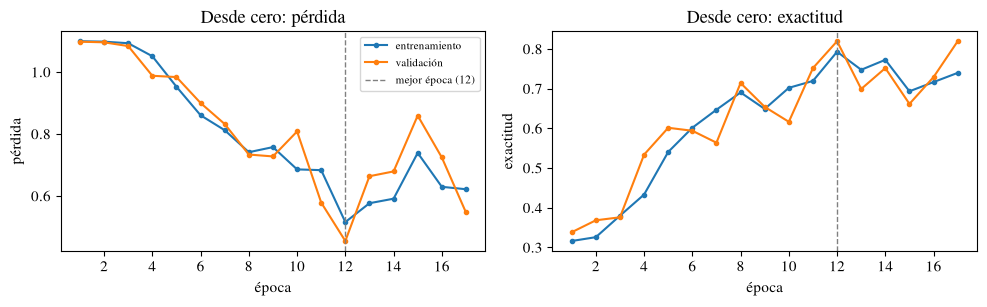

Desde cero: exactitud en prueba = 0.773 | tiempo = 3.7 min


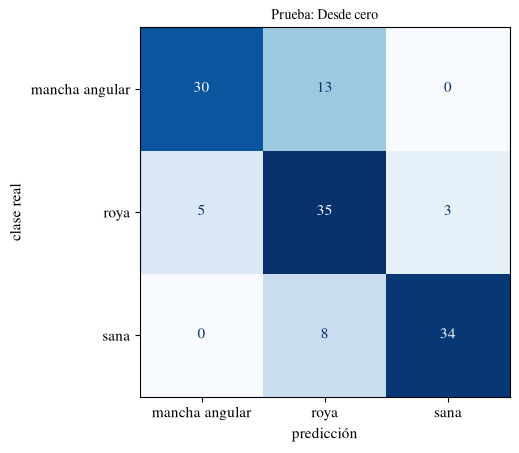

In [14]:
torch.manual_seed(SEED)
modelo_cero = models.alexnet(weights=None, num_classes=len(CLASES))
assert contar_parametros(modelo_cero) == (57_016_131, 0)

ajuste_cero = fit(modelo_cero, **ESTRATEGIAS["desde_cero"])
graficar_curvas(ajuste_cero, ETIQUETA["desde_cero"])
evaluar_test(modelo_cero, "desde_cero", ajuste_cero)

**Interpretación.** Aprende, pero lento e inestable: tras 3 épocas casi al azar (~33 %) sube hasta 82.0 % en validación (época 12) y luego oscila, por lo que la parada temprana lo detiene en la época 17. En prueba logra **77.3 %**; su error principal es confundir mancha angular con roya (13 de 43). Con 1034 imágenes, 57 M de parámetros aleatorios no alcanzan a aprender buenas características.

## 6. Demo 2: solo la capa clasificadora

Se cargan los pesos de ImageNet, se congela **todo** y se **agrega una capa nueva** (dense3:
4096→3) que es lo único que se entrena. Las características aprendidas en ImageNet se reutilizan
para un problema específico.

In [15]:
torch.manual_seed(SEED)
try:
    modelo_ext = models.alexnet(weights=models.AlexNet_Weights.IMAGENET1K_V1)
except Exception as e:
    raise RuntimeError(f"No se pudieron obtener los pesos ImageNet ({URL_PESOS}) en {CACHE_DIR}/") from e

for p in modelo_ext.parameters():
    p.requires_grad = False                                   # congela lo aprendido en ImageNet
modelo_ext.classifier[6] = nn.Linear(4096, len(CLASES))       # capa nueva: entrenable por defecto

assert contar_parametros(modelo_ext) == (12_291, 57_003_840)
display(tabla_entrenables(modelo_ext))

,Capa,Parámetros,Entrenable
0,conv1,23296,False
1,conv2,307392,False
2,conv3,663936,False
3,conv4,884992,False
4,conv5,590080,False
5,dense1,37752832,False
6,dense2,16781312,False
7,dense3,12291,True


época  1 | train loss 0.747 acc 0.683 | val loss 0.376 acc 0.850


época  2 | train loss 0.478 acc 0.817 | val loss 0.351 acc 0.865


época  3 | train loss 0.450 acc 0.819 | val loss 0.450 acc 0.820


época  4 | train loss 0.394 acc 0.838 | val loss 0.406 acc 0.865


época  5 | train loss 0.460 acc 0.824 | val loss 0.282 acc 0.880


época  6 | train loss 0.341 acc 0.873 | val loss 0.300 acc 0.872


época  7 | train loss 0.415 acc 0.838 | val loss 0.252 acc 0.902


época  8 | train loss 0.335 acc 0.874 | val loss 0.296 acc 0.887


época  9 | train loss 0.331 acc 0.869 | val loss 0.278 acc 0.880


época 10 | train loss 0.314 acc 0.876 | val loss 0.287 acc 0.887


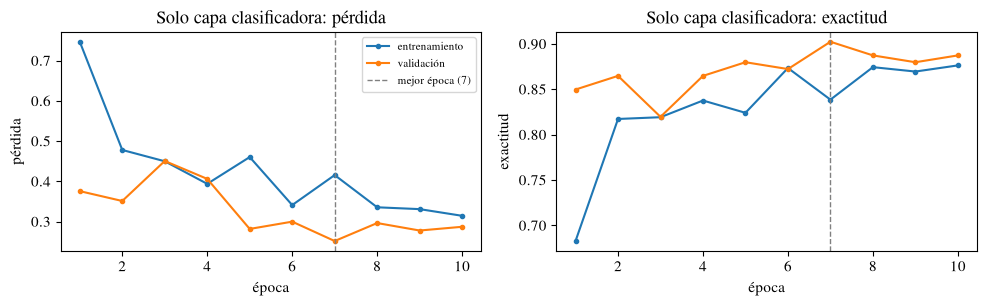

Solo capa clasificadora: exactitud en prueba = 0.859 | tiempo = 0.8 min


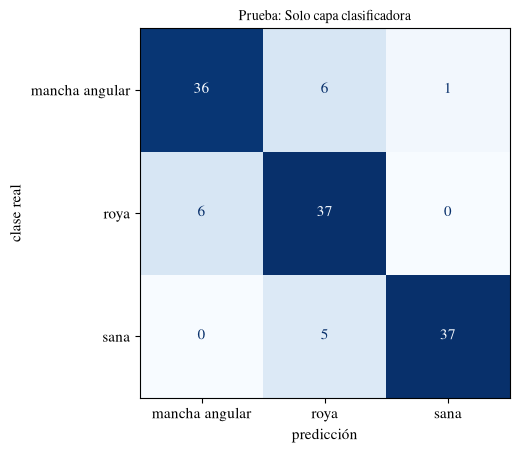

In [16]:
ajuste_ext = fit(modelo_ext, **ESTRATEGIAS["extraccion"])
graficar_curvas(ajuste_ext, ETIQUETA["extraccion"])
evaluar_test(modelo_ext, "extraccion", ajuste_ext)

**Interpretación.** Desde la primera época ya tiene 85 % en validación: las características de ImageNet sirven para hojas de frijol aunque no sean una clase de ImageNet. Entrenando solo 12 291 parámetros (0.02 % del modelo) en 0.8 min logra **85.9 %** en prueba, 8.6 puntos más que desde cero en una quinta parte del tiempo.

## 7. Demo 3: *fine-tuning*

Se parte del modelo de la demo 2, de modo que la capa nueva ya no es aleatoria. Se **descongelan
conv4 y conv5**, que tienen las características más específicas de ImageNet, y se mantienen
congeladas conv1–conv3 (bordes y texturas genéricas) y dense1–dense2. El LR es 10 veces menor
(1e-4) para ajustar sin destruir los pesos preentrenados.

In [17]:
modelo_ft = copy.deepcopy(modelo_ext)
for capa in (modelo_ft.features[8], modelo_ft.features[10]):      # conv4 y conv5
    for p in capa.parameters():
        p.requires_grad = True

assert contar_parametros(modelo_ft)[0] == 1_487_363
tabla_ft = tabla_entrenables(modelo_ft)
display(tabla_ft)
assert tabla_ft.set_index("Capa")["Entrenable"].to_dict() == {
    "conv1": False, "conv2": False, "conv3": False, "conv4": True, "conv5": True,
    "dense1": False, "dense2": False, "dense3": True}

,Capa,Parámetros,Entrenable
0,conv1,23296,False
1,conv2,307392,False
2,conv3,663936,False
3,conv4,884992,True
4,conv5,590080,True
5,dense1,37752832,False
6,dense2,16781312,False
7,dense3,12291,True


época  1 | train loss 0.278 acc 0.874 | val loss 0.247 acc 0.902


época  2 | train loss 0.287 acc 0.901 | val loss 0.244 acc 0.910


época  3 | train loss 0.263 acc 0.898 | val loss 0.240 acc 0.902


época  4 | train loss 0.272 acc 0.891 | val loss 0.239 acc 0.910


época  5 | train loss 0.270 acc 0.898 | val loss 0.232 acc 0.902


época  6 | train loss 0.268 acc 0.894 | val loss 0.231 acc 0.917


época  7 | train loss 0.260 acc 0.897 | val loss 0.233 acc 0.917


época  8 | train loss 0.269 acc 0.901 | val loss 0.226 acc 0.917


época  9 | train loss 0.251 acc 0.898 | val loss 0.217 acc 0.925


época 10 | train loss 0.259 acc 0.892 | val loss 0.216 acc 0.925


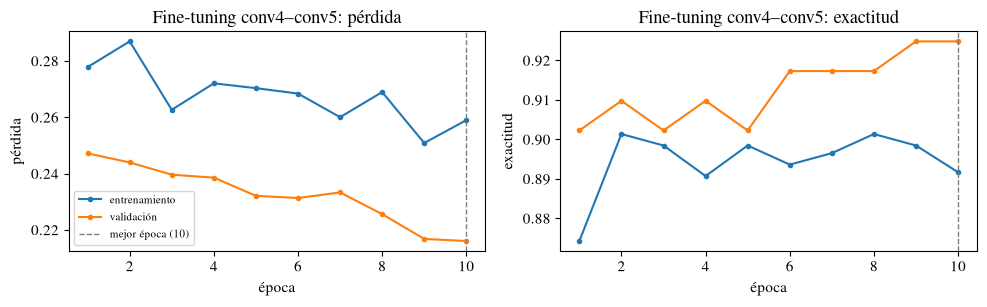

Fine-tuning conv4–conv5: exactitud en prueba = 0.859 | tiempo = 1.2 min


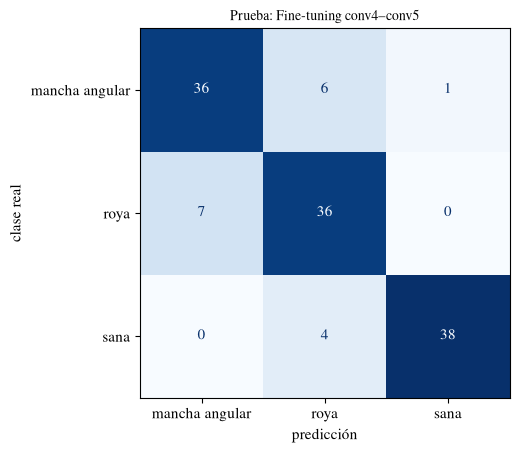

In [18]:
torch.manual_seed(SEED)
ajuste_ft = fit(modelo_ft, **ESTRATEGIAS["fine_tuning"])
graficar_curvas(ajuste_ft, ETIQUETA["fine_tuning"])
evaluar_test(modelo_ft, "fine_tuning", ajuste_ft)

**Interpretación.** Ajustar conv4–conv5 mejora la validación (90.2 % → 92.5 %) y la pérdida aún baja en la época 10, señal de que más épocas podrían ayudar. En prueba empata con la demo 2 (**85.9 %**, 110 de 128): con 128 imágenes cada acierto vale 0.8 puntos, así que la mejora en validación no alcanza a notarse en prueba.

## 8. Comparación
La tabla y las figuras se exportan al informe (`informe/generated/`, `informe/figures/`).

,estrategia,params_entrenables,epocas_ejecutadas,mejor_epoca,tiempo_min,val_acc,test_acc
0,desde_cero,57016131,17,12,3.704,0.820,0.773
1,extraccion,12291,10,7,0.755,0.902,0.859
2,fine_tuning,1487363,10,10,1.191,0.925,0.859


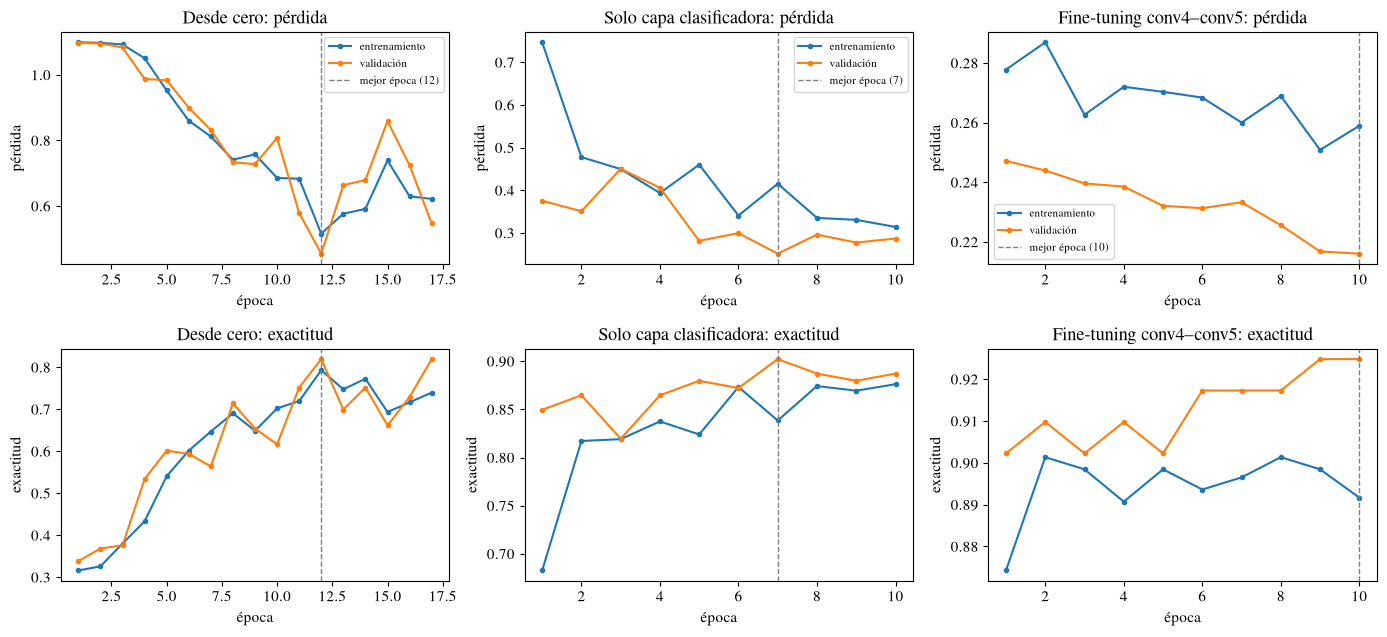

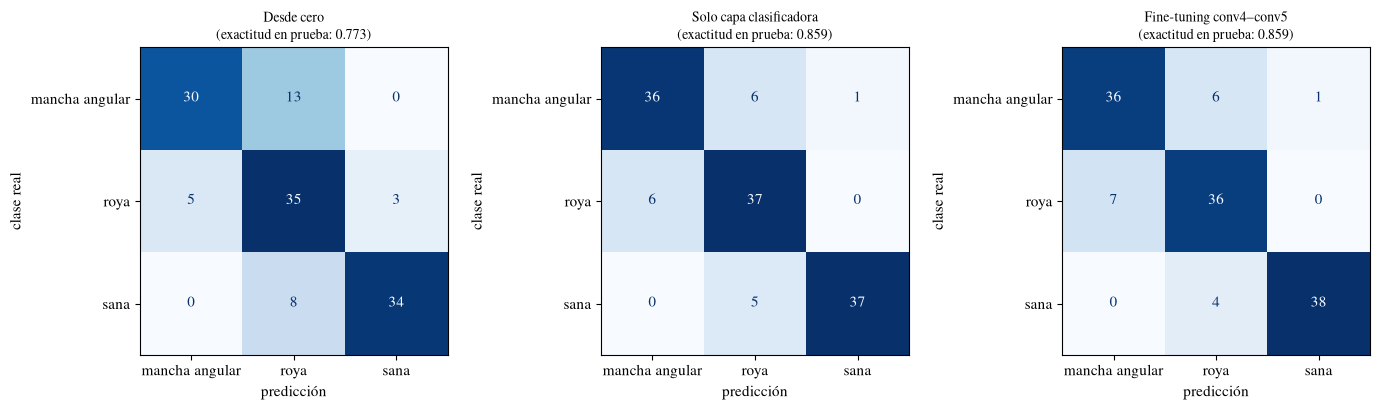

In [19]:
inicio_s8 = time.time()
assert set(RESULTADOS) == set(ESTRATEGIAS), "faltan demos por ejecutar"
filas = [RESULTADOS[k] for k in ESTRATEGIAS]
comparacion = pd.DataFrame([{k: v for k, v in r.items() if k not in ("matriz", "historia")}
                            for r in filas])
display(comparacion.round(3))

resultados_tex = pd.DataFrame({
    "Estrategia": [ETIQUETA[r["estrategia"]] for r in filas],
    "Parámetros entrenables": [int(r["params_entrenables"]) for r in filas],
    "Épocas (mejor)": [f"{r['epocas_ejecutadas']} ({r['mejor_epoca']})" for r in filas],
    "Tiempo (min)": [f"{r['tiempo_min']:.1f}" for r in filas],
    "Exactitud val.": [f"{r['val_acc']:.3f}" for r in filas],
    "Exactitud prueba": [f"{r['test_acc']:.3f}" for r in filas]})
a_latex(resultados_tex, GEN_DIR / "resultados.tex", "§8")

fig, axes = plt.subplots(2, 3, figsize=(14, 6.5))
for j, k in enumerate(ESTRATEGIAS):
    ajuste = {"historia": RESULTADOS[k]["historia"], "mejor_epoca": RESULTADOS[k]["mejor_epoca"]}
    graficar_curvas(ajuste, ETIQUETA[k], axes=axes[:, j])
fig.tight_layout(); fig.savefig(FIG_DIR / "curvas.png", dpi=200); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
for ax, k in zip(axes, ESTRATEGIAS):
    graficar_matriz(RESULTADOS[k]["matriz"],
                    f"{ETIQUETA[k]}\n(exactitud en prueba: {RESULTADOS[k]['test_acc']:.3f})", ax=ax)
fig.tight_layout(); fig.savefig(FIG_DIR / "matrices_confusion.png", dpi=200); plt.show()

for ruta in (GEN_DIR / "resultados.tex", FIG_DIR / "curvas.png", FIG_DIR / "matrices_confusion.png"):
    assert ruta.exists() and ruta.stat().st_mtime >= inicio_s8, ruta
assert (GEN_DIR / "entrenamiento.tex").exists() and (GEN_DIR / "arquitectura.tex").exists()

## 9. Conclusiones

- **La transferencia supera al entrenamiento desde cero:** 85.9 % frente a 77.3 % en prueba
  (+8.6 puntos), algo menos que los +10 esperados; con solo 128 imágenes de prueba la diferencia
  equivale a 11 aciertos.
- **Es mucho más barata:** 12 291 parámetros entrenables frente a 57 M, y unas 4–5 veces menos
  tiempo de entrenamiento (tabla anterior).
- **El *fine-tuning* da la mejor validación (92.5 %)**, pero en prueba empata con la demo 2; la
  diferencia no es concluyente con este tamaño de prueba.
- **El error dominante en las tres estrategias es mancha angular ↔ roya**, ambas lesiones de la
  hoja; *sana* es la clase más fácil.
- **El conjunto de datos importa:** una primera ejecución con Rock-Paper-Scissors (imágenes
  sintéticas, fáciles) dio 99.5 % desde cero frente a 96 % con transferencia, así que no mostraba el
  beneficio esperado; por eso se usa Beans (fotografías reales de un dominio nuevo).

## 10. Referencias

- Deng, J., Dong, W., Socher, R., Li, L.-J., Li, K., & Fei-Fei, L. (2009). ImageNet: A large-scale
  hierarchical image database. *2009 IEEE Conference on Computer Vision and Pattern Recognition*,
  248–255.
- Krizhevsky, A. (2014). *One weird trick for parallelizing convolutional neural networks*
  (arXiv:1404.5997). arXiv.
- Krizhevsky, A., Sutskever, I., & Hinton, G. E. (2012). ImageNet classification with deep
  convolutional neural networks. *Advances in Neural Information Processing Systems, 25*, 1106–1114.
- Makerere AI Lab. (2020). *Bean disease dataset* [Conjunto de datos].
  https://github.com/AI-Lab-Makerere/ibean/
- PyTorch. (s.f.). *AlexNet: torchvision models documentation*.
  https://pytorch.org/vision/stable/models/alexnet.html